# Notebook 01: Data Audit

**Project:** Credit Decision Assistant
**Data:** Lending Club loans issued between 2007 and 2018 (about 2.26 million loans)

## What this notebook is for

The project will eventually take a loan application, estimate how likely the person is to stop paying it back, suggest whether to lend and on what terms, and explain the decision in plain English.

Before any of that, I need to understand the raw data properly. This notebook does not build a model or change anything about the data. It only looks, measures and writes down what it finds, so that the decisions in the later notebooks are based on evidence rather than guesses.

It answers five questions:

1. **Is the file intact?** How many rows are real loans, are there any junk rows, are there duplicates?
2. **When was the data taken?** Every "how old is this loan" calculation depends on this date.
3. **How finished is each year's group of loans?** Recent loans are mostly still being repaid, and that turns out to matter a lot.
4. **Which columns exist in which years?** Lending Club added and removed fields over time.
5. **Did Lending Club change its own rules over time?** Loan limits, pricing, the mix of customers.

## A few terms used in this notebook

| Term | What it means here |
|---|---|
| **Loan status** | Where the loan stood when the data was taken: Fully Paid, Current (still being repaid on time), Late, Charged Off, and so on. |
| **Default / Charged Off** | The borrower stopped paying. After roughly five months of missed payments, Lending Club gives up on the loan and writes it off as a loss. That write-off is called a *charge-off*. |
| **Term** | How long the borrower has to repay: 36 or 60 months. |
| **Maturity** | The end of the term, when the last scheduled payment is due. |
| **Prepayment** | Paying the loan off early, before maturity. Very common. |
| **Vintage** | All loans issued in the same period (here usually the same year). "The 2016 vintage" means loans issued in 2016. |
| **Snapshot date** | The month the data was extracted. Anything that happened after it is invisible to us. |
| **Credit bureau** | A company that keeps records of people's borrowing history (credit cards, other loans, missed payments). Lenders pull this report when someone applies. |
| **FICO score** | A credit score between 300 and 850 summarising that history. Higher means more reliable. |
| **Grade** | Lending Club's own risk rating for each loan, from A (safest) to G (riskiest). It also sets the interest rate. |

## What this notebook produces

- `data/interim/loans_raw.parquet`: a fast, compressed copy of the raw CSV. No rows or columns removed.
- `data/interim/loans_raw_schema.json`: which columns are numbers and which are text.
- `data/interim/loan_index.parquet`: one row per real loan, with the dates and status fields the next notebook needs.
- `data/interim/audit_config.json`: the snapshot date and the scope decisions made here, so later notebooks read them instead of retyping them.

## Setup

Imports, display settings, and every folder path defined in one place. All paths are built relative to the project folder, so the notebook works on any machine with the same folder structure. The `assert` stops everything straight away if the raw file can't be found, which usually means the notebook was opened from the wrong folder.

In [1]:
from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
import pyarrow as pa                 # Arrow: the in-memory format behind Parquet
import pyarrow.parquet as pq         # reading and writing Parquet files
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Display settings: show more columns, and print numbers with thousands separators
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# This notebook lives in credit-default/notebooks/, so the project folder is one level up.
# Every path in the notebook is built from PROJECT_ROOT, so nothing is hard-coded.
PROJECT_ROOT = Path.cwd().parent
RAW_DIR      = PROJECT_ROOT / "data" / "raw"          # original files, never modified
INTERIM_DIR  = PROJECT_ROOT / "data" / "interim"      # outputs of this notebook
FIG_DIR      = PROJECT_ROOT / "outputs" / "figures"
TABLE_DIR    = PROJECT_ROOT / "outputs" / "tables"

RAW_LOANS = RAW_DIR / "loan.csv"
assert RAW_LOANS.exists(), f"Not found: {RAW_LOANS}"   # stop early if the path is wrong

print(f"Project root: {PROJECT_ROOT}")
print(f"pandas {pd.__version__} | numpy {np.__version__} | pyarrow {pa.__version__}")
print(f"loan.csv: {RAW_LOANS.stat().st_size / 1e9:.2f} GB")

Project root: /Users/sourodeeproy/Desktop/credit-default
pandas 3.1.0 | numpy 2.5.4 | pyarrow 26.0.0
loan.csv: 1.68 GB


## Step 1: How much memory would the full file need?

The raw file is a 1.68 GB CSV, and my laptop has 8 GB of RAM. Loading a CSV into pandas takes a lot more memory than the file size, so before trying to load it I measured a small piece and scaled up.

**How:** read 100,000 rows, measure how much memory they actually use (`deep=True` makes pandas count the real size of text values, not just pointers to them), then scale to the full row count:

$$\text{estimated memory} = 143 \text{ MB} \times \frac{2{,}260{,}701}{100{,}000} \approx 3.2 \text{ GB}$$

That 3.2 GB is the finished table. While pandas is reading a CSV it also holds the raw text and half-built columns at the same time, so the peak is usually 1.5 to 2 times higher: roughly 5 to 6.5 GB. With macOS and VS Code already using a few GB, loading everything at once would push the laptop into swapping memory to disk, or crash the notebook.

**A second thing showed up:** pandas guessed the column types from these 100,000 rows as 114 numeric, 36 text and 1 integer column. The next step shows that guess is wrong for the full file.

**Result:** the file should be processed in pieces, and column types should be decided from the whole file, not a sample.

In [2]:
# 1. Read only the header row to see how many columns there are
header = pd.read_csv(RAW_LOANS, nrows=0)
print(f"Columns: {len(header.columns)}")

# 2. Read the first 100,000 rows and measure how much memory they really take
t0 = time.time()
sample = pd.read_csv(RAW_LOANS, nrows=100_000, low_memory=False)
print(f"Read 100k rows in {time.time() - t0:.1f}s")

# deep=True counts the actual size of text values, not just the pointers to them
mem_sample = sample.memory_usage(deep=True).sum()
TOTAL_ROWS_APPROX = 2_260_701          # approximate; the exact count is confirmed during conversion
est_full_gb = mem_sample * TOTAL_ROWS_APPROX / len(sample) / 1e9   # scale the sample up to the full file

print(f"Sample memory:            {mem_sample / 1e6:,.0f} MB")
print(f"Projected full-file load: {est_full_gb:,.1f} GB (excluding parsing overhead)")

# What types did pandas guess from these 100k rows? (Step 2 checks this against the whole file)
print("\nColumn dtypes in sample:")
print(sample.dtypes.astype(str).value_counts())

Columns: 151
Read 100k rows in 0.3s
Sample memory:            143 MB
Projected full-file load: 3.2 GB (excluding parsing overhead)

Column dtypes in sample:
float64    114
str         36
int64        1
Name: count, dtype: int64


## Step 2: Decide each column's type using the whole file

When pandas reads a CSV it guesses each column's type from the values it sees. If it only sees part of the file, it can guess wrong. That matters here because the next step writes the data into a format that needs **one fixed type per column** for the entire file.

**How:** read the CSV in chunks of 250,000 rows with every column treated as plain text, so pandas doesn't guess anything. For each column, count the values that are present but can't be turned into a number. A column with zero such values across all 2.26 million rows is numeric. Anything else is text. Empty cells are ignored in this count, because a missing value tells us nothing about whether a column is numeric.

The `id` column is kept as text no matter what. It's a label, not something to do maths with.

**Result:**
- 2,260,701 rows: **113 numeric columns and 38 text columns**.
- The 100,000-row sample got two columns wrong:
  - `id`: numeric in the first 100,000 rows, but 33 rows further down contain text. These turn out to be summary rows, not loans (see Step 4).
  - `sec_app_earliest_cr_line`: the co-applicant's oldest credit account date. It's completely empty in the first 100,000 rows because joint applications didn't exist yet in those loans, so pandas called it a number. Later in the file it holds text dates like "Aug-2001".
- If each chunk had been allowed to guess its own types, these two columns would have changed type halfway through the file.

In [3]:
CHUNK_ROWS = 250_000            # rows per chunk: about half a GB of memory at a time
cols = header.columns.tolist()

n_rows       = 0
non_null     = pd.Series(0, index=cols, dtype="int64")   # values present, per column
non_numeric  = pd.Series(0, index=cols, dtype="int64")   # values present but not a number, per column

t0 = time.time()
# dtype=str: read everything as plain text, so pandas makes no guesses about types
reader = pd.read_csv(RAW_LOANS, dtype=str, chunksize=CHUNK_ROWS)
for i, chunk in enumerate(reader, start=1):
    n_rows   += len(chunk)
    non_null += chunk.notna().sum()
    for c in cols:
        s = chunk[c].dropna()            # ignore empty cells: they say nothing about the type
        if len(s):
            # errors="coerce" turns anything that isn't a number into NaN, so we can count those
            non_numeric[c] += pd.to_numeric(s, errors="coerce").isna().sum()
    print(f"  chunk {i:>2}: {n_rows:>10,} rows scanned  ({time.time() - t0:5.1f}s)")

# A column is numeric only if every single value in the file parses as a number.
# id is a label, never something to calculate with, so it stays text regardless.
numeric_cols = [c for c in cols if non_numeric[c] == 0 and c != "id"]
text_cols    = [c for c in cols if c not in numeric_cols]

print(f"\nTotal rows in file: {n_rows:,}")
print(f"Numeric columns: {len(numeric_cols)} | Text columns: {len(text_cols)}")

# Which columns did the 100k-row sample get wrong?
sample_numeric = set(sample.select_dtypes(include="number").columns)
disagree = sorted((sample_numeric - set(numeric_cols)) | (set(numeric_cols) - sample_numeric))
print(f"\nColumns where the sample's guess differs from the full-file schema: {disagree}")

# Columns that are numbers almost everywhere but contain a few text values: worth a closer look
suspicious = non_numeric[(non_numeric > 0) & (non_numeric < 0.01 * non_null)]
print("\nMostly numeric but with some non-numeric values:")
print(suspicious.to_string() if len(suspicious) else "  none")

  chunk  1:    250,000 rows scanned  (  8.1s)
  chunk  2:    500,000 rows scanned  ( 16.9s)
  chunk  3:    750,000 rows scanned  ( 26.0s)
  chunk  4:  1,000,000 rows scanned  ( 34.8s)
  chunk  5:  1,250,000 rows scanned  ( 43.2s)
  chunk  6:  1,500,000 rows scanned  ( 51.6s)
  chunk  7:  1,750,000 rows scanned  ( 60.0s)
  chunk  8:  2,000,000 rows scanned  ( 68.1s)
  chunk  9:  2,250,000 rows scanned  ( 77.1s)
  chunk 10:  2,260,701 rows scanned  ( 77.6s)

Total rows in file: 2,260,701
Numeric columns: 113 | Text columns: 38

Columns where the sample's guess differs from the full-file schema: ['id', 'sec_app_earliest_cr_line']

Mostly numeric but with some non-numeric values:
id    33


## Step 3: Convert the CSV into a Parquet file (done once)

From here on, every notebook needs to read this data. Reading the CSV takes over a minute each time and too much memory, so I converted it once into **Parquet**, a file format built for exactly this.

**CSV vs Parquet, in short:**

| | CSV | Parquet |
|---|---|---|
| Layout | Row by row, as text | Column by column, as real numbers and text |
| Reading 5 of the 151 columns | Still has to read and split every row | Reads only those 5 columns |
| Numbers | Stored as text ("24700.0") and converted on every load | Stored as numbers, no conversion needed |
| Repeated text like "36 months" | Written out millions of times | Stored once, with a small code per row |
| Column types | Guessed on every load | Fixed and saved inside the file |

**Why in chunks:** the converter reads 250,000 rows, writes them, frees the memory, then reads the next 250,000. Memory use stays at about one chunk (roughly half a GB) no matter how big the file is. Each chunk becomes a block inside the same Parquet file, not a separate file.

A few details in the code:
- `.astype("float64")` forces every numeric column to the same type in every chunk. Without it, a chunk with no missing values would come out as whole numbers and a chunk with missing values as decimals, and the file would reject the mismatch.
- The schema (the fixed list of column types) acts like a contract. If a chunk ever didn't match it, the code would raise an error instead of quietly writing bad data.
- `try / finally` makes sure the file is closed properly even if something fails. Parquet only writes its index at the very end, and a file without it can't be opened.
- Nothing is cleaned here. The Parquet file is an exact copy of the CSV, junk rows included. Cleaning happens in the following steps, where it can be seen and explained.

**Result:** 2,260,701 rows and 151 columns in both files. **0.29 GB instead of 1.68 GB (about 6 times smaller)**, and 4 full columns load in 3.7 seconds. The CSV is not read again after this.

In [4]:
RAW_PARQUET = INTERIM_DIR / "loans_raw.parquet"

# The fixed list of column types decided in Step 2: numbers as float64, everything else as text.
# Every chunk written below must match this exactly.
schema = pa.schema(
    [(c, pa.float64()) if c in numeric_cols else (c, pa.string()) for c in cols]
)

t0 = time.time()
rows_written = 0
writer = pq.ParquetWriter(RAW_PARQUET, schema, compression="zstd")   # zstd: fast, strong compression
try:
    for i, chunk in enumerate(pd.read_csv(RAW_LOANS, dtype=str, chunksize=CHUNK_ROWS), start=1):
        # Turn the numeric columns from text into numbers. Forcing float64 keeps every chunk
        # identical, even chunks with no missing values (which pandas would otherwise make int64).
        for c in numeric_cols:
            chunk[c] = pd.to_numeric(chunk[c], errors="coerce").astype("float64")
        # Converting with the schema raises an error if the chunk doesn't match it
        table = pa.Table.from_pandas(chunk, schema=schema, preserve_index=False)
        writer.write_table(table)        # each chunk becomes one block inside the same file
        rows_written += len(chunk)
        print(f"  chunk {i:>2}: {rows_written:>10,} rows written  ({time.time() - t0:5.1f}s)")
finally:
    writer.close()          # always close: Parquet writes its index at the end, without it the file can't be read

# Keep a record of which columns are numbers and which are text
with open(INTERIM_DIR / "loans_raw_schema.json", "w") as f:
    json.dump({"numeric_cols": numeric_cols, "text_cols": text_cols}, f, indent=2)

# Checks: same number of rows as the CSV, the size saving, and how fast a few columns now load
meta = pq.read_metadata(RAW_PARQUET)
print(f"\nRows in Parquet:  {meta.num_rows:,}  (CSV had {n_rows:,})")
print(f"Columns:          {meta.num_columns}")
print(f"File size:        {RAW_PARQUET.stat().st_size / 1e9:.2f} GB  (CSV: {RAW_LOANS.stat().st_size / 1e9:.2f} GB)")

t0 = time.time()
test = pd.read_parquet(RAW_PARQUET, columns=["id", "issue_d", "loan_status", "loan_amnt"])
print(f"Loaded 4 columns x {len(test):,} rows in {time.time() - t0:.1f}s")
assert meta.num_rows == n_rows, "Row count mismatch between CSV and Parquet"

  chunk  1:    250,000 rows written  (  7.6s)
  chunk  2:    500,000 rows written  ( 14.9s)
  chunk  3:    750,000 rows written  ( 23.2s)
  chunk  4:  1,000,000 rows written  ( 31.3s)
  chunk  5:  1,250,000 rows written  ( 38.4s)
  chunk  6:  1,500,000 rows written  ( 46.0s)
  chunk  7:  1,750,000 rows written  ( 53.3s)
  chunk  8:  2,000,000 rows written  ( 60.4s)
  chunk  9:  2,250,000 rows written  ( 67.7s)
  chunk 10:  2,260,701 rows written  ( 68.1s)

Rows in Parquet:  2,260,701  (CSV had 2,260,701)
Columns:          151
File size:        0.29 GB  (CSV: 1.68 GB)
Loaded 4 columns x 2,260,701 rows in 3.7s


## Step 4: Are all the rows real loans?

From now on I only load the columns this audit needs: about 30 out of 151. That takes under a second and uses 0.8 GB.

**How:** any row with no loan status can't be a loan. I compared those rows with the 33 rows from Step 2 whose `id` wasn't a number, to check they are the same rows, and printed what they contain.

**Result:**
- Exactly 33 rows have no status, and they are the same 33 rows with a text `id`.
- They contain summary lines like *"Total amount funded in policy code 1: 6417608175"*.
- They appear **in pairs throughout the file**, not just at the end.

That last point explains what this file really is. Lending Club published its loan data as separate downloads (one per year for early years, one per quarter later), and each download ended with a couple of summary lines. The Kaggle file is **several of those downloads stuck together**, and each pair of summary lines marks the join between two of them.

In [5]:
# Only the columns this audit needs: IDs, loan details, dates, outcome, and a few columns
# from each group of fields, used in Step 8 to see when each group exists
AUDIT_COLS = [
    "id", "loan_amnt", "funded_amnt", "term", "int_rate", "grade", "sub_grade",
    "purpose", "application_type", "fico_range_low",
    "issue_d", "loan_status", "last_pymnt_d", "next_pymnt_d", "last_credit_pull_d", "earliest_cr_line",
    "total_rec_prncp", "recoveries",
    # one or two columns from each group of fields, to check when each group appears
    "desc", "emp_title", "mths_since_recent_inq", "acc_open_past_24mths", "num_tl_op_past_12m",
    "tot_cur_bal", "open_acc_6m", "all_util", "annual_inc_joint", "sec_app_fico_range_low",
    "mort_acc", "revol_util",
]

t0 = time.time()
df = pd.read_parquet(RAW_PARQUET, columns=AUDIT_COLS)
print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns in {time.time() - t0:.1f}s "
      f"| memory {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

# A row with no loan status can't be a loan
junk = df["loan_status"].isna()
print(f"\nRows with missing loan_status: {junk.sum()}")

# Are these the same rows that had a text id in Step 2?
id_not_numeric = pd.to_numeric(df["id"], errors="coerce").isna()
print(f"Rows with non-numeric id:      {id_not_numeric.sum()}")
print(f"Same rows?                     {(junk == id_not_numeric).all()}")

# Show what these rows contain, hiding the columns that are empty for them
print("\nWhat the junk rows contain (non-empty columns only):")
print(df.loc[junk].dropna(axis=1, how="all").head(10).to_string())

Loaded 2,260,701 rows x 30 columns in 0.7s | memory 0.81 GB

Rows with missing loan_status: 33
Rows with non-numeric id:      33
Same rows?                     True

What the junk rows contain (non-empty columns only):
                                                      id
421095  Total amount funded in policy code 1: 6417608175
421096  Total amount funded in policy code 2: 1944088810
528961  Total amount funded in policy code 1: 1741781700
528962   Total amount funded in policy code 2: 564202131
651664  Total amount funded in policy code 1: 1791201400
651665   Total amount funded in policy code 2: 651669342
749520  Total amount funded in policy code 1: 1443412975
749521   Total amount funded in policy code 2: 511988838
877716  Total amount funded in policy code 1: 2063142975
877717   Total amount funded in policy code 2: 823319310


### Tag each loan with the download it came from, then remove the summary rows

If the original downloads were taken on different dates, each would have its own snapshot date, and a single date for the whole file would be wrong. So before deleting the summary rows, I used them to label which download each loan came from.

**How the label works:** mark summary rows as 1 and real loans as 0, then take a running total down the file. Every loan gets the number of summary rows above it:

```
row:            a   b   SUMMARY   c   d   SUMMARY   e
summary flag:   0   0      1      0   0      1      0
running total:  0   0      1      1   1      2      2   <- segment number
```

Two summary rows in a row produce a segment number with no loans, so some numbers are skipped. That's expected.

**Result:**
- **2,260,668 real loans** in **17 segments**, with **no duplicate loan IDs**. A duplicated loan would be counted twice in every rate calculated later.
- The segment sizes match the original Lending Club downloads: a 2015 file (421,095 loans), a 2014 file (235,629), a 2012 to 2013 file (188,181), twelve quarterly files for 2016 to 2018, and a 2007 to 2011 file split into two parts.
- One of those parts has exactly **2,749** loans, the same as the number of loans marked "Does not meet the credit policy" in the status column (1,988 + 761). Lending Club listed those older loans that didn't meet its lending rules in a separate section of that file, with one extra separator line. That also explains why there are 33 summary rows (an odd number) rather than an even count.

In [6]:
# Each summary row closes one of the original downloads. A running count of summary rows
# above each loan tells us which download (segment) the loan came from.
df["source_segment"] = junk.cumsum().astype("int16")

# Now remove the summary rows themselves
df = df.loc[~junk].copy()
print(f"Loans after removing footer rows: {len(df):,}")
print(f"Source segments: {df['source_segment'].nunique()}")
print(df["source_segment"].value_counts().sort_index().to_string())

# Every loan must appear exactly once, or it would be counted twice in every rate
n_dup = df["id"].duplicated().sum()
print(f"\nDuplicated ids: {n_dup}")
assert n_dup == 0, "Duplicate loan ids: investigate before continuing"

# The loan status labels as they appear in the data
print("\nloan_status values:")
print(df["loan_status"].value_counts().to_string())

Loans after removing footer rows: 2,260,668
Source segments: 17
source_segment
0     421095
2     107864
4     122701
6      97854
8     128194
10    105451
12    133887
14    235629
16    128412
18    130772
20     39786
21      2749
23     96779
25    188181
27     99120
29    118648
31    103546

Duplicated ids: 0

loan_status values:
loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40


## Step 5: Dates, and when the data was taken

Dates are stored as text like "Dec-2015". I converted the five date columns into real dates, using the exact format so pandas doesn't have to guess. Any value that doesn't match the format would be counted as a failure. There were none.

| Column | Meaning |
|---|---|
| `issue_d` | Month the loan was given out |
| `last_pymnt_d` | Month of the most recent payment received |
| `next_pymnt_d` | Next payment due (only for loans still running) |
| `last_credit_pull_d` | Last time Lending Club refreshed the borrower's credit report |
| `earliest_cr_line` | When the borrower opened their first credit account |

**Finding the snapshot date:** a loan that is still on time made a payment in the latest month before the data was taken. So the most recent `last_pymnt_d` in the data should be that month. I checked this overall and separately for each of the 17 downloads.

**Result:**
- The snapshot is **March 2019**, and 94% of on-time loans made their last payment in exactly that month, which confirms it. (The other 6% paid a month or two earlier, which is normal: some people pay ahead.)
- Two segments, the 2007 to 2011 files, show an earlier latest payment (April 2017 and January 2016). That isn't an older download. Every loan in them had already finished, so there was simply nothing left to pay, and their credit reports were still being refreshed in March 2019 like every other segment. **One snapshot date applies to all the data.**
- 2,427 loans have no payment date at all: these borrowers never made a single payment.

In [7]:
DATE_COLS = ["issue_d", "last_pymnt_d", "next_pymnt_d", "last_credit_pull_d", "earliest_cr_line"]

# Convert "Dec-2015" style text into real dates. Giving the exact format means pandas
# doesn't guess, and anything that doesn't match becomes NaT (missing) so we can count it.
parse_report = {}
for c in DATE_COLS:
    raw_non_null = df[c].notna().sum()
    df[c] = pd.to_datetime(df[c], format="%b-%Y", errors="coerce")
    parse_report[c] = {"raw_non_null": raw_non_null,
                       "parse_failures": raw_non_null - df[c].notna().sum(),
                       "min": df[c].min(), "max": df[c].max()}
display(pd.DataFrame(parse_report).T)

# For each original download: which months it covers, its latest payment and credit report
# dates, and how many of its loans are still being repaid
current = df["loan_status"].eq("Current")
seg = df.groupby("source_segment").agg(
    n_loans            = ("id", "size"),
    issue_from         = ("issue_d", "min"),
    issue_to           = ("issue_d", "max"),
    max_last_pymnt     = ("last_pymnt_d", "max"),
    max_credit_pull    = ("last_credit_pull_d", "max"),
    share_current      = ("loan_status", lambda s: (s == "Current").mean()),
)
display(seg)

# Snapshot = the latest month in which any payment was received
SNAPSHOT = df["last_pymnt_d"].max()
print(f"Global snapshot (max last_pymnt_d): {SNAPSHOT:%b-%Y}")
# Check: most loans still being repaid should have paid in exactly that month
print(f"Current loans whose last payment is in the snapshot month: "
      f"{(df.loc[current, 'last_pymnt_d'] == SNAPSHOT).mean():.1%}")
print(f"Segments whose own max last_pymnt_d differs from the global snapshot: "
      f"{(seg['max_last_pymnt'] != SNAPSHOT).sum()}")

,raw_non_null,parse_failures,min,max
issue_d,2260668,0,2007-06-01 00:00:00,2018-12-01 00:00:00
last_pymnt_d,2258241,0,2007-12-01 00:00:00,2019-03-01 00:00:00
next_pymnt_d,915358,0,2008-01-01 00:00:00,2019-05-01 00:00:00
last_credit_pull_d,2260596,0,2007-05-01 00:00:00,2019-04-01 00:00:00
earliest_cr_line,2260639,0,1933-03-01 00:00:00,2015-11-01 00:00:00


,n_loans,issue_from,issue_to,max_last_pymnt,max_credit_pull,share_current
source_segment,,,,,,
0,421095,2015-01-01,2015-12-01,2019-03-01,2019-03-01,0.1028
2,107864,2018-01-01,2018-03-01,2019-03-01,2019-04-01,0.7614
4,122701,2017-07-01,2017-09-01,2019-03-01,2019-03-01,0.6123
6,97854,2016-04-01,2016-06-01,2019-03-01,2019-03-01,0.3412
8,128194,2018-07-01,2018-09-01,2019-03-01,2019-03-01,0.8972
10,105451,2017-04-01,2017-06-01,2019-03-01,2019-03-01,0.5519
12,133887,2016-01-01,2016-03-01,2019-03-01,2019-03-01,0.1519
14,235629,2014-01-01,2014-12-01,2019-03-01,2019-03-01,0.0506
16,128412,2018-10-01,2018-12-01,2019-03-01,2019-03-01,0.9475


Global snapshot (max last_pymnt_d): Mar-2019
Current loans whose last payment is in the snapshot month: 94.0%
Segments whose own max last_pymnt_d differs from the global snapshot: 2


## Step 6: How old was each loan when the data was taken?

I grouped the nine loan statuses into four simple outcomes:

| Group | Statuses |
|---|---|
| paid | Fully Paid |
| charged_off | Charged Off |
| current | Current (still repaying on time) |
| delinquent_active | Late by various amounts, or seriously late but not yet written off |

The two "Does not meet the credit policy" versions are mapped to the same groups as their normal counterparts.

Then, for each loan issued in month $t$, its age at the snapshot $S$ in months is:

$$\text{age} = 12 \times (\text{year of } S - \text{year of } t) + (\text{month of } S - \text{month of } t)$$

A loan has **matured** if its age is at least its term (36 or 60 months), and it has **resolved** if it has finished one way or another (paid or charged off).

The last column of the table is the **resolved-only default rate**: out of the loans that have finished, what share were charged off.

$$\text{resolved-only default rate} = \frac{\text{charged off}}{\text{paid} + \text{charged off}}$$

This looks like a sensible way to measure how risky each year's loans were. The table shows why it isn't.

**Result:**
- Loans from 2013 and earlier have all finished, so their rate is the real one (15.6% for 2013).
- Only 38% of 2017 loans had finished by March 2019. Those 38% are people who either stopped paying early or paid off early. The 59% still paying normally, who will mostly end up Fully Paid, are left out completely. Dividing 8.8% charged off by only 38.1% finished gives **23.1%**, which looks much worse than 2013 but mostly reflects how few loans had finished.
- 2018 shows 15.7%, which looks like an improvement, but those loans were so young that most people who will eventually stop paying hadn't done so yet.

So this rate changes depending on **when you look**, not just on how risky the borrowers were. The next step measures by how much.

In [8]:
def status_group(s: pd.Series) -> pd.Series:
    """Collapse the nine loan statuses into four simple outcomes."""
    # Remove the "Does not meet the credit policy" prefix so both versions map the same way
    s = s.str.replace("Does not meet the credit policy. Status:", "", regex=False)
    mapping = {
        "Fully Paid": "paid",
        "Charged Off": "charged_off",
        "Current": "current",
        "In Grace Period": "delinquent_active",       # a few days late
        "Late (16-30 days)": "delinquent_active",
        "Late (31-120 days)": "delinquent_active",
        "Default": "delinquent_active",               # over 120 days late, not yet written off
    }
    out = s.map(mapping)
    assert out.notna().all(), f"Unmapped statuses: {s[out.isna()].unique()}"
    return out

df["status_group"] = status_group(df["loan_status"])
df["meets_policy"] = ~df["loan_status"].str.startswith("Does not meet")
df["term_m"]       = df["term"].str.extract(r"(\d+)")[0].astype("int8")    # " 36 months" -> 36
df["issue_year"]   = df["issue_d"].dt.year.astype("int16")
# Age of the loan at the snapshot, in whole months
df["age_at_S"]     = ((SNAPSHOT.year - df["issue_d"].dt.year) * 12
                      + (SNAPSHOT.month - df["issue_d"].dt.month)).astype("int16")
df["matured"]      = df["age_at_S"] >= df["term_m"]                       # had time to reach the end of its term
df["resolved"]     = df["status_group"].isin(["paid", "charged_off"])     # has finished one way or the other
# int8 / int16 types keep these new columns small in memory

print(df["status_group"].value_counts().to_string())

# For each issue year: outcome shares, size, share of 60-month loans, how many had matured
# and finished, and the default rate calculated on finished loans only
comp = pd.crosstab(df["issue_year"], df["status_group"], normalize="index")[
    ["paid", "charged_off", "current", "delinquent_active"]]
comp["n_loans"]          = df.groupby("issue_year").size()
comp["share_60m"]        = df.groupby("issue_year")["term_m"].apply(lambda t: (t == 60).mean())
comp["share_matured"]    = df.groupby("issue_year")["matured"].mean()
comp["share_resolved"]   = df.groupby("issue_year")["resolved"].mean()
comp["resolved_only_dr"] = (df[df["resolved"]].groupby("issue_year")["status_group"]
                              .apply(lambda g: (g == "charged_off").mean()))

pct_cols = [c for c in comp.columns if c != "n_loans"]
display(comp.style.format({**{c: "{:.1%}" for c in pct_cols}, "n_loans": "{:,}"}))

status_group
paid                 1078739
current               878317
charged_off           269320
delinquent_active      34292


status_group,paid,charged_off,current,delinquent_active,n_loans,share_60m,share_matured,share_resolved,resolved_only_dr
issue_year,,,,,,,,,
2007,73.8%,26.2%,0.0%,0.0%,603,0.0%,100.0%,100.0%,26.2%
2008,79.3%,20.7%,0.0%,0.0%,"2,393",0.0%,100.0%,100.0%,20.7%
2009,86.3%,13.7%,0.0%,0.0%,"5,281",0.0%,100.0%,100.0%,13.7%
2010,86.0%,14.0%,0.0%,0.0%,"12,537",27.0%,100.0%,100.0%,14.0%
2011,84.8%,15.2%,0.0%,0.0%,"21,721",35.1%,100.0%,100.0%,15.2%
2012,83.8%,16.2%,0.0%,0.0%,"53,367",18.5%,100.0%,100.0%,16.2%
2013,84.4%,15.6%,0.0%,0.0%,"134,814",25.5%,100.0%,100.0%,15.6%
2014,77.2%,17.5%,5.1%,0.3%,"235,629",31.0%,74.7%,94.7%,18.4%
2015,71.2%,18.0%,10.3%,0.5%,"421,095",32.8%,67.2%,89.2%,20.2%


## Step 7: Measuring how wrong the resolved-only rate can be

**The idea:** take groups of old loans that have **completely finished**. For those, the true default rate is known. Then pretend the data had been taken earlier, when those loans were only a few months old, and recalculate the resolved-only rate. Comparing the two shows exactly how wrong the rate is at each age. This uses real data and no model.

To do that, I need the month each loan finished:

- **Paid loans:** the month of the last payment.
- **Charged-off loans:** the data has no write-off date, only the last payment received. The next payment would have been due a month later, and Lending Club writes a loan off roughly 150 days (5 months) after that. So I used last payment + 6 months. Borrowers who never paid are counted from the month the loan was issued.

Because the 6 months is an estimate, I also re-run the experiment with 4 and 8 months to check whether the conclusion depends on it.

**Result of this cell:**
- The 2,427 loans with no payment date are 2,325 charged-off loans and 102 still-late loans. No paid loan is missing a payment date, which makes sense.
- I expected defaults to finish much earlier than paid loans. They don't: the middle values are similar (20 months for charged-off 36-month loans, 22 for paid). What differs is the **shape**:

| 36-month loans | 10% | 25% | 50% | 75% | 90% |
|---|---|---|---|---|---|
| Charged off (month finished) | 10 | 14 | 20 | 27 | 33 |
| Paid (month finished) | 5 | 12 | 22 | 35 | 36 |

Paid loans finish in two clumps: people who pay off early, and people who simply reach the end of the term. Charged-off loans are concentrated in the middle. That difference in shape is what drives the bias below.

In [9]:
def months_between(later: pd.Series, earlier: pd.Series) -> pd.Series:
    """Whole months between two month-level dates."""
    return (later.dt.year - earlier.dt.year) * 12 + (later.dt.month - earlier.dt.month)

paid = df["status_group"].eq("paid")
co   = df["status_group"].eq("charged_off")

# Months from issue to the last payment received (missing if the borrower never paid)
df["months_to_last_pymnt"] = months_between(df["last_pymnt_d"], df["issue_d"]).astype("float32")

print("Loans with no payment ever, by outcome:")
print(df.loc[df["last_pymnt_d"].isna(), "status_group"].value_counts().to_string())

def resolution_age(lag_m: int) -> pd.Series:
    """Month (counted from issue) in which each finished loan finished.
    Paid loans: the last payment. Charged-off loans: the last payment plus lag_m months,
    since the write-off happens months after payments stop. Never-paid loans count from issue."""
    out = pd.Series(np.nan, index=df.index, dtype="float32")
    out[paid] = df.loc[paid, "months_to_last_pymnt"]
    out[co]   = df.loc[co, "months_to_last_pymnt"].fillna(0) + lag_m
    return out

CHARGEOFF_LAG_M = 6     # one month to the first missed payment, plus about 5 months until write-off
df["resolution_age"] = resolution_age(CHARGEOFF_LAG_M)

# When do paid and charged-off loans finish? Split by term
print("\nResolution age (months after issue) for resolved loans:")
display(df.loc[df["resolved"]]
          .groupby(["term_m", "status_group"])["resolution_age"]
          .describe(percentiles=[.1, .25, .5, .75, .9]).round(1))

Loans with no payment ever, by outcome:
status_group
charged_off          2325
delinquent_active     102

Resolution age (months after issue) for resolved loans:


count    mean     std    min     10%     25%     50%     75%     90%     max
term_m status_group                                                                                    
36     charged_off  163,901.0000 20.8000  8.6000 6.0000 10.0000 14.0000 20.0000 27.0000 33.0000 68.0000
       paid         859,280.0000 21.9000 11.8000 0.0000  5.0000 12.0000 22.0000 35.0000 36.0000 70.0000
60     charged_off  105,419.0000 23.7000 11.5000 6.0000 11.0000 15.0000 21.0000 31.0000 40.0000 72.0000
       paid         219,459.0000 22.9000 16.5000 0.0000  4.0000  9.0000 20.0000 34.0000 48.0000 70.0000

### The experiment: pretend the data was taken earlier

Write $p$ for the true default rate of a group, $G_1(c)$ for the share of eventual defaulters who have finished by age $c$, and $G_0(c)$ for the share of eventual payers who have finished by age $c$. Then the resolved-only rate at age $c$ works out to:

$$\text{resolved-only rate}(c) = \frac{p \cdot G_1(c)}{p \cdot G_1(c) + (1 - p) \cdot G_0(c)}$$

In words: if defaulters have finished faster than payers at that age ($G_1 > G_0$), the rate is **too high**. If payers have finished faster ($G_1 < G_0$), it's **too low**. It only equals the truth once everyone has finished.

The two groups used are fully finished: **36-month loans issued in 2012 to 2013** (true default rate 12.7%) and **60-month loans issued in 2012** (true default rate 27.7%). The `bias_ratio` column is the resolved-only rate divided by the true rate, so 1.00x means correct and 1.40x means 40% too high.

**Result:**

| Age when "looked at" | 36-month loans | 60-month loans |
|---|---|---|
| 6 months | 0.15x (far too low) | 0.07x |
| 12 months | 0.92x | 0.80x |
| 18 to 30 months | 1.31x to 1.41x (too high) | 1.15x to 1.31x |
| 36 to 54 months | about 1.00x | 1.20x to 1.31x (still too high) |
| after the term ends | 1.00x | 1.00x |

Early on, mostly people who paid off early have finished, so the rate is too low. In the middle of the term, most of the eventual defaulters have finished but the large group who simply pay to the end hasn't, so the rate is too high. It only settles once everyone is done.

**Does the 6-month write-off guess matter?** The sensitivity table re-runs this with 4 and 8 months:
- In the middle of the term (24 months, and 24 to 36 months for 60-month loans) the rate is too high under every assumption, by roughly 20% to 50%. **That conclusion holds.**
- Around 12 months, the direction flips depending on the assumption (1.32x, 0.92x, 0.57x). **That part can't be trusted.**

A side note: the 60-month group defaults more than twice as often as the 36-month group (27.7% vs 12.7%). Longer loans give more time for things to go wrong, and riskier borrowers are more often given longer terms.

In [10]:
def pseudo_snapshot_curve(cohort: pd.DataFrame, res_age: pd.Series, ages) -> pd.DataFrame:
    """For a fully finished group of loans, the resolved-only default rate we would have
    calculated if the data had been taken at each age c, next to the true default rate."""
    is_co  = cohort["status_group"].eq("charged_off")
    true_p = is_co.mean()                               # the real answer: everyone has finished
    rows = []
    for c in ages:
        seen = res_age.loc[cohort.index] <= c           # loans that would have finished by age c
        rows.append({"age_c": c,
                     "share_resolved": seen.mean(),
                     "resolved_only_dr": is_co[seen].mean() if seen.any() else np.nan,
                     "true_lifetime_dr": true_p})
    out = pd.DataFrame(rows)
    out["bias_ratio"] = out["resolved_only_dr"] / out["true_lifetime_dr"]   # 1.00x = correct
    return out

# Two groups that had completely finished by March 2019 (100% resolved in Step 6)
cohorts = {
    "36m, issued 2012-2013": df[(df["term_m"] == 36) & df["issue_year"].between(2012, 2013) & df["meets_policy"]],
    "60m, issued 2012":      df[(df["term_m"] == 60) & (df["issue_year"] == 2012) & df["meets_policy"]],
}

curves = {}
for name, coh in cohorts.items():
    term = int(coh["term_m"].iloc[0])
    print(f"\n{name}: n = {len(coh):,} | resolved: {coh['resolved'].mean():.2%} | "
          f"true lifetime DR: {coh['status_group'].eq('charged_off').mean():.2%}")
    # Pretend the data was taken every 3 months from age 6 to just past the end of the term
    curves[name] = pseudo_snapshot_curve(coh, df["resolution_age"], range(6, term + 7, 3))
    display(curves[name].iloc[::2].style.format({
        "share_resolved": "{:.1%}", "resolved_only_dr": "{:.1%}",
        "true_lifetime_dr": "{:.1%}", "bias_ratio": "{:.2f}x"}))

# Sensitivity check: repeat with a 4 and an 8 month write-off delay instead of 6
sens = []
for lag in (4, 6, 8):
    ra = resolution_age(lag)
    for name, coh in cohorts.items():
        cur = pseudo_snapshot_curve(coh, ra, [12, 24, 36])
        for _, r in cur.iterrows():
            sens.append({"cohort": name, "lag_m": lag, "age_c": r["age_c"], "bias_ratio": r["bias_ratio"]})
display(pd.DataFrame(sens).pivot_table(index=["cohort", "age_c"], columns="lag_m", values="bias_ratio")
          .style.format("{:.2f}x"))


36m, issued 2012-2013: n = 143,892 | resolved: 100.00% | true lifetime DR: 12.70%


,age_c,share_resolved,resolved_only_dr,true_lifetime_dr,bias_ratio
0,6,4.7%,1.9%,12.7%,0.15x
2,12,14.4%,11.7%,12.7%,0.92x
4,18,27.0%,16.6%,12.7%,1.31x
6,24,41.0%,17.8%,12.7%,1.40x
8,30,54.5%,17.9%,12.7%,1.41x
10,36,92.7%,12.5%,12.7%,0.99x
12,42,99.9%,12.7%,12.7%,1.00x



60m, issued 2012: n = 9,897 | resolved: 100.00% | true lifetime DR: 27.70%


,age_c,share_resolved,resolved_only_dr,true_lifetime_dr,bias_ratio
0,6,4.8%,1.9%,27.7%,0.07x
2,12,13.0%,22.1%,27.7%,0.80x
4,18,23.5%,31.9%,27.7%,1.15x
6,24,34.4%,35.4%,27.7%,1.28x
8,30,45.1%,36.3%,27.7%,1.31x
10,36,55.3%,36.2%,27.7%,1.31x
12,42,64.3%,35.2%,27.7%,1.27x
14,48,71.4%,34.4%,27.7%,1.24x
16,54,78.6%,33.1%,27.7%,1.20x
18,60,95.1%,28.6%,27.7%,1.03x


### The same result as a picture

The red line is the resolved-only rate if the data had been taken at that age. The dashed line is the true rate. The grey area is the share of the group that had finished. The red line starts below the truth, rises above it in the middle of the term, and only meets it once the grey area reaches 100%.

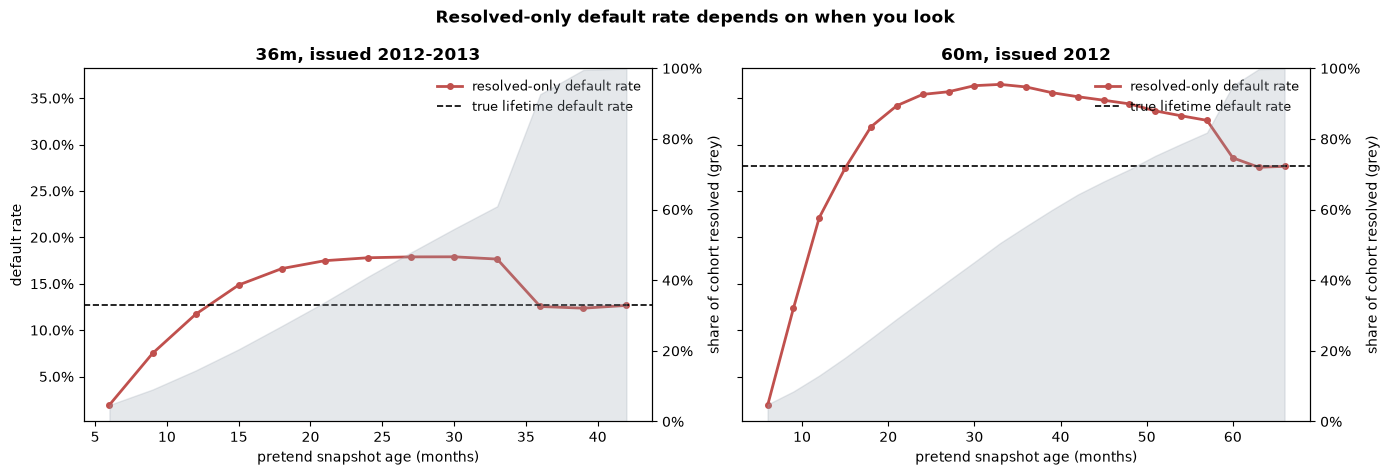

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, (name, cur) in zip(axes, curves.items()):
    # Red: the resolved-only rate at each pretend age. Dashed: the true rate.
    ax.plot(cur["age_c"], cur["resolved_only_dr"], marker="o", ms=4, lw=2,
            color="#C0504D", label="resolved-only default rate")
    ax.axhline(cur["true_lifetime_dr"].iloc[0], color="black", ls="--", lw=1.2,
               label="true lifetime default rate")
    # Grey area on a second axis: share of the group that had finished by that age
    ax2 = ax.twinx()
    ax2.fill_between(cur["age_c"], cur["share_resolved"], color="#9AA5B1", alpha=0.25)
    ax2.set_ylim(0, 1)
    ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax2.set_ylabel("share of cohort resolved (grey)")
    ax.set_title(name, fontweight="bold")
    ax.set_xlabel("pretend snapshot age (months)")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.legend(loc="lower right", frameon=False, fontsize=9)
axes[0].set_ylabel("default rate")
fig.suptitle("Resolved-only default rate depends on when you look", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_censoring_bias_pseudo_snapshot.png", dpi=150)
plt.show()

### Where the recent years sit on those curves

This table shows how old each recent year's loans were in March 2019 and what share had finished, split by term. Reading each row against the curves above shows which resolved-only rates can be trusted.

**Result:**
- **Trustworthy:** 36-month loans from 2014 (aged 51 to 62 months) and 2015 (aged 39 to 50 months). They are past their term and almost entirely finished. Their rates are 13.7% and 14.9%.
- **Too high:** every 60-month row, because none of those loans had reached the end of their term. And 36-month loans from 2016 and 2017, which sit in the middle-of-term zone.
- **Not usable:** 2018 loans, aged 3 to 14 months.

Using only the trustworthy rows, the true default rate for 36-month loans rose from **12.7% (2012 to 2013) to 13.7% (2014) to 14.9% (2015)**. That's a real but modest increase, much smaller than the jump to 20% or more that the resolved-only rate suggests for 2016 and 2017.

**What this means for the project:** the target the model learns from can't be "did this loan eventually default", calculated on finished loans only. Instead, every loan will be judged over **the same fixed window: did the borrower stop paying within the first 12 months?** Any loan that has been around for at least 12 months can answer that question, whether it's finished or not. And since the write-off timing is unreliable right around 12 months, the moment of default will be dated by the **first missed payment**, which comes straight from the data, instead of the write-off date. Notebook 02 builds this.

In [13]:
# For each recent year and term: how old the loans were at the snapshot, how many had
# finished, and the resolved-only default rate
recent = df[df["issue_year"] >= 2014]
tbl = recent.groupby(["issue_year", "term_m"]).agg(
    n_loans         = ("id", "size"),
    age_min         = ("age_at_S", "min"),
    age_max         = ("age_at_S", "max"),
    share_resolved  = ("resolved", "mean"),
)
tbl["resolved_only_dr"] = (recent[recent["resolved"]]
                             .groupby(["issue_year", "term_m"])["status_group"]
                             .apply(lambda g: (g == "charged_off").mean()))
display(tbl.style.format({"n_loans": "{:,}", "share_resolved": "{:.1%}", "resolved_only_dr": "{:.1%}"}))

## Step 8: Which columns exist in which years?

A column can look 95% complete overall and still be completely empty for several years, simply because Lending Club hadn't started collecting it yet. That's a problem for modelling. If a column is missing for all the old loans and present for all the new ones, the model can learn "missing means old loan" instead of learning anything about the borrower. And since the model will be trained on older loans and tested on newer ones, it would effectively be learning to tell the two apart.

**How:** for a selection of columns, the share of loans where the value is present, by year. The joint-application fields are checked separately, because for single applicants they are empty by design rather than missing.

**Result:**

| Columns | Available |
|---|---|
| `revol_util` (how much of their credit card limits people are using), `emp_title` | Every year |
| Credit bureau details (accounts opened recently, total balances, number of mortgages, recent credit checks) | Not at all before 2012, partly in 2012, fully from **2013** |
| Newer credit bureau details (`open_acc_6m`, `all_util`) | Only from **2016** |
| `desc` (the borrower's own written description) | Disappears by 2015 |
| Joint applications (two people applying together) | Almost none before 2016, then 2% to 14% of loans |

**Decisions this leads to** (recorded in the config file, applied in Notebook 03):
1. **Only loans issued from 2013 onwards are used for modelling.** From then on the important credit bureau fields are always there. This drops about 96,000 early loans (around 4% of the data).
2. **The newer bureau fields are left out of the main model**, because they only exist from 2016 and the main model is trained on earlier loans. They can be tested separately later.
3. **Only individual applications are in scope.** A model trained mostly on loans from before 2016 would hardly ever see a joint application, so it couldn't score one reliably.

Not every gap is about time, though. `mths_since_recent_inq` (months since a lender last checked the person's credit) is around 90% present even in recent years. A missing value there most likely means *no recent check at all*, which is useful information in itself, and it will be treated that way.

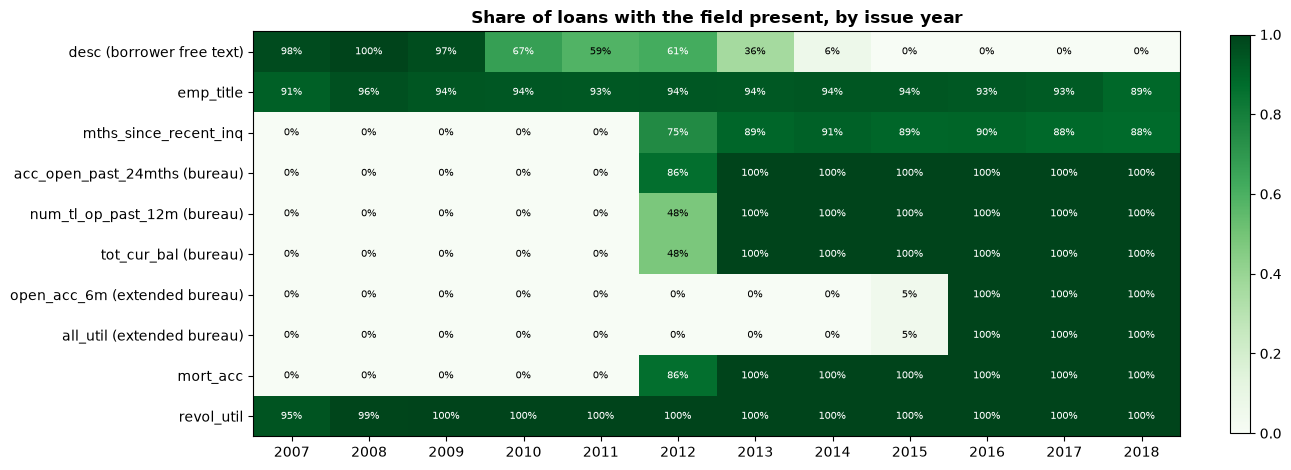

Share of joint applications by year:
issue_year
2007     0.0%
2008     0.0%
2009     0.0%
2010     0.0%
2011     0.0%
2012     0.0%
2013     0.0%
2014     0.0%
2015     0.1%
2016     2.0%
2017     9.6%
2018    13.9%

annual_inc_joint present among joint applications: 100.0%


In [14]:
# One or two columns from each group of fields, with a readable label for the chart
probe_cols = {
    "desc (borrower free text)":       "desc",
    "emp_title":                       "emp_title",
    "mths_since_recent_inq":           "mths_since_recent_inq",
    "acc_open_past_24mths (bureau)":   "acc_open_past_24mths",
    "num_tl_op_past_12m (bureau)":     "num_tl_op_past_12m",
    "tot_cur_bal (bureau)":            "tot_cur_bal",
    "open_acc_6m (extended bureau)":   "open_acc_6m",
    "all_util (extended bureau)":      "all_util",
    "mort_acc":                        "mort_acc",
    "revol_util":                      "revol_util",
}
# Share of loans where each column has a value, by issue year (rows = columns, columns = years)
avail = pd.DataFrame({label: df[col].notna().groupby(df["issue_year"]).mean()
                      for label, col in probe_cols.items()}).T

fig, ax = plt.subplots(figsize=(13, 4.8))
im = ax.imshow(avail.values, aspect="auto", cmap="Greens", vmin=0, vmax=1)
ax.set_xticks(range(avail.shape[1]), avail.columns)
ax.set_yticks(range(avail.shape[0]), avail.index)
# Write the percentage in each cell (white text on dark cells, black on light ones)
for i in range(avail.shape[0]):
    for j in range(avail.shape[1]):
        v = avail.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7.5,
                color="white" if v > 0.6 else "black")
ax.set_title("Share of loans with the field present, by issue year", fontweight="bold")
plt.colorbar(im, ax=ax, fraction=0.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_field_availability.png", dpi=150)
plt.show()

# Joint-application fields are empty for single applicants by design,
# so the meaningful check is how complete they are for joint applications
joint = df["application_type"].eq("Joint App")
print("Share of joint applications by year:")
print(joint.groupby(df["issue_year"]).mean().map("{:.1%}".format).to_string())
print("\nannual_inc_joint present among joint applications:",
      f"{df.loc[joint, 'annual_inc_joint'].notna().mean():.1%}")

## Step 9: Did Lending Club change its own rules over time?

The model will learn from older loans and be tested on newer ones. That only works if the patterns stay reasonably stable. Changes on Lending Club's side can break that, so I checked the maximum loan size, the share of 60-month loans, typical credit scores, the mix of grades, and the interest rate charged for each grade.

**Result:**
- **The maximum loan went up twice:** $25,000 until 2010, $35,000 from 2011 and $40,000 from 2016. Any feature built by splitting loan amounts into ranges on older data would have a top range ending at $35,000, so the ranges will need open-ended top and bottom bands.
- **The share of 60-month loans** moves between about 25% and 33% in the years that will be modelled. That matters because 60-month loans default far more often.
- **Customers got safer, but pricing for riskier grades went up.** The share of A and B grade loans rose from about 42% in 2014 to about 56% in 2018, and the median FICO score rose from 685 to 700. At the same time, the interest rate for grade E loans went from 19.0% to 25.3% between 2015 and 2018, and grades F and G rose similarly. Grade A stayed flat at around 7.2%. So a "grade E" loan in 2018 is not the same thing as a "grade E" loan in 2015.

**An important decision:** the grade, sub-grade and interest rate are **not facts about the borrower**. They are Lending Club's own verdict on the borrower, produced by its internal model. Using them in this project's model would cause two problems:

1. **The system would be going round in circles.** In this project, the decision engine sets the interest rate *based on* the model's risk estimate. If the risk estimate also used the interest rate as an input, each would depend on the other.
2. **A real lender wouldn't have them.** Someone filling in a loan application has their income, debts and credit history, not a Lending Club grade.

So `grade`, `sub_grade`, `int_rate` and `installment` (the monthly payment, which is calculated from the rate) are **left out of the model**. They are the strongest predictors in the data, so the model's accuracy will be lower than one that uses them. But it will be honest about what can be predicted from the applicant alone. Comparing the two later will show how much of Lending Club's own model can be reproduced from the applicant's information.

,n_loans,max_loan,p99_loan,share_60m,median_fico
issue_year,,,,,
2007,603,"$25,000","$25,000",0.0%,680
2008,"2,393","$25,000","$25,000",0.0%,690
2009,"5,281","$25,000","$25,000",0.0%,710
2010,"12,537","$25,000","$25,000",27.0%,710
2011,"21,721","$35,000","$35,000",35.1%,710
2012,"53,367","$35,000","$35,000",18.5%,695
2013,"134,814","$35,000","$35,000",25.5%,690
2014,"235,629","$35,000","$35,000",31.0%,685
2015,"421,095","$35,000","$35,000",32.8%,685


Median interest rate (%) by grade and issue year:


issue_year,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
grade,,,,,,,,,,,,
A,7.8,8.3,8.9,7.1,7.3,7.9,7.9,7.7,6.9,7.2,7.2,7.2
B,9.3,10.4,11.8,10.8,11.0,12.1,12.0,11.4,10.0,10.5,10.5,10.9
C,10.9,11.8,13.2,13.5,13.5,15.3,15.6,14.2,13.3,13.7,14.1,14.5
D,12.5,13.3,15.0,15.2,16.5,18.5,18.6,17.0,17.0,18.0,19.0,19.4
E,14.1,14.8,16.4,16.8,18.6,21.0,21.6,20.2,19.0,22.4,24.9,25.3
F,15.5,16.1,18.2,18.7,20.6,23.3,23.8,24.1,24.0,25.7,30.0,29.7
G,17.5,18.3,20.1,20.5,22.1,24.7,25.8,25.8,26.8,28.7,30.9,30.8


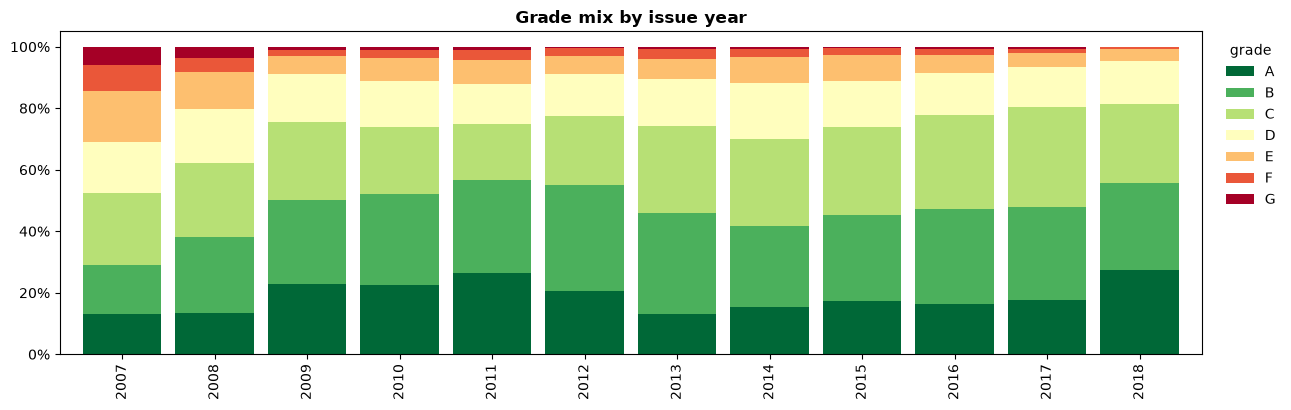

In [15]:
# Platform-level changes by year: loan size limit, share of 60-month loans, typical credit score
policy = df.groupby("issue_year").agg(
    n_loans     = ("id", "size"),
    max_loan    = ("loan_amnt", "max"),
    p99_loan    = ("loan_amnt", lambda s: s.quantile(0.99)),
    share_60m   = ("term_m", lambda t: (t == 60).mean()),
    median_fico = ("fico_range_low", "median"),
)
display(policy.style.format({"n_loans": "{:,}", "max_loan": "${:,.0f}", "p99_loan": "${:,.0f}",
                             "share_60m": "{:.1%}", "median_fico": "{:.0f}"}))

# Median interest rate for each grade in each year: does a grade mean the same price over time?
rate_by_grade = df.pivot_table(index="grade", columns="issue_year", values="int_rate", aggfunc="median")
print("Median interest rate (%) by grade and issue year:")
# Shading runs along each row, so a grade whose price drifted shows a colour change across years
display(rate_by_grade.style.format("{:.1f}").background_gradient(axis=1, cmap="Oranges"))

# Grade mix by year: is Lending Club lending to safer or riskier people over time?
grade_mix = pd.crosstab(df["issue_year"], df["grade"], normalize="index")
fig, ax = plt.subplots(figsize=(13, 4.2))
grade_mix.plot(kind="bar", stacked=True, ax=ax, colormap="RdYlGn_r", width=0.85)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Grade mix by issue year", fontweight="bold")
ax.set_xlabel("")
ax.legend(title="grade", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_grade_mix.png", dpi=150)
plt.show()

## Step 10: Save what the next notebooks need

- **`loan_index.parquet`**: one row per real loan with its ID, source file, dates, term, amount, status and the age fields worked out above (22 MB). The next notebook only needs these to build the target. All the other columns stay in `loans_raw.parquet` and will be joined back by loan ID when building features.
- **`audit_config.json`**: the snapshot date, row counts and the scope decisions from Steps 8 and 9. Later notebooks read their settings from this file, so the numbers can't drift apart between notebooks.

The scope decisions are only **written down** here. They are applied in Notebook 03. This notebook stays a pure description of the data.

In [16]:
# One row per real loan, with only the fields the next notebook needs to build the target.
# Every other column stays in loans_raw.parquet and is joined back by id later.
INDEX_COLS = [
    "id", "source_segment", "issue_d", "issue_year", "term_m", "loan_amnt",
    "loan_status", "status_group", "meets_policy", "application_type",
    "last_pymnt_d", "months_to_last_pymnt", "age_at_S", "matured", "resolved",
]
loan_index = df[INDEX_COLS].copy()
index_path = INTERIM_DIR / "loan_index.parquet"
loan_index.to_parquet(index_path, index=False)

# Settings every later notebook must agree on. They read this file instead of retyping values.
config = {
    "snapshot": SNAPSHOT.strftime("%Y-%m"),
    "date_format": "%b-%Y",
    "n_rows_raw_file": int(n_rows),
    "n_footer_rows_removed": int(junk.sum()),
    "n_loans": int(len(df)),
    "status_counts": {k: int(v) for k, v in df["status_group"].value_counts().items()},
    # Decided in Steps 8 and 9, applied in Notebook 03
    "scope": {
        "min_issue_year": 2013,              # key credit bureau fields are complete from 2013
        "application_type": "Individual",    # joint applications barely exist before 2016
        "exclude_extended_bureau_core": ["open_acc_6m", "all_util"],   # only exist from 2016
        "exclude_pricing_fields": ["grade", "sub_grade", "int_rate", "installment"],   # Lending Club's own verdict
    },
    "notes": {
        "default_timing": "Date default by first missed payment (last_pymnt_d + 1 month), not by charge-off",
        "loan_cap_changes": {"2011": 35000, "2016": 40000},
    },
}
with open(INTERIM_DIR / "audit_config.json", "w") as f:
    json.dump(config, f, indent=2)

print(f"Saved {index_path.name}: {loan_index.shape[0]:,} rows x {loan_index.shape[1]} cols "
      f"({index_path.stat().st_size / 1e6:.0f} MB)")
print(json.dumps(config, indent=2))

Saved loan_index.parquet: 2,260,668 rows x 15 cols (22 MB)
{
  "snapshot": "2019-03",
  "date_format": "%b-%Y",
  "n_rows_raw_file": 2260701,
  "n_footer_rows_removed": 33,
  "n_loans": 2260668,
  "status_counts": {
    "paid": 1078739,
    "current": 878317,
    "charged_off": 269320,
    "delinquent_active": 34292
  },
  "scope": {
    "min_issue_year": 2013,
    "application_type": "Individual",
    "exclude_extended_bureau_core": [
      "open_acc_6m",
      "all_util"
    ],
    "exclude_pricing_fields": [
      "grade",
      "sub_grade",
      "int_rate",
      "installment"
    ]
  },
  "notes": {
    "default_timing": "Date default by first missed payment (last_pymnt_d + 1 month), not by charge-off",
    "loan_cap_changes": {
      "2011": 35000,
      "2016": 40000
    }
  }
}


## Findings

1. **The file is clean once 33 summary rows are removed.** It holds 2,260,668 loans with no duplicates. The summary rows show the file is 17 separate Lending Club downloads joined together.
2. **The data was taken in March 2019.** This holds for every download; the two older files only look different because all of their loans had already finished.
3. **Measuring default only on loans that have finished gives misleading results.** The rate depends on how old the loans are when you look. It can be far too low early on and 20% to 50% too high in the middle of the term, and it only becomes correct once every loan has finished. This was measured directly by "rewinding" fully finished loans, and the middle-of-term result holds under different assumptions about write-off timing.
4. **So the project will use a fixed 12-month window as its target:** did the borrower stop paying within the first 12 months? Every loan observed for at least 12 months can answer it fairly. The default will be dated by the first missed payment rather than the write-off date, because the write-off timing is the least reliable piece of information right around 12 months.
5. **The true default rate for 36-month loans that have fully finished** rose modestly over time: 12.7% for 2012 to 2013, 13.7% for 2014 and 14.9% for 2015.
6. **Important credit bureau fields only exist from 2013, newer ones only from 2016, and joint applications only appear from 2016.** The model will therefore use loans from 2013 onwards, individual applications only, and leave the newest bureau fields out of the main model.
7. **Lending Club's grade and interest rate are its own assessment, and their meaning shifted over time.** They are left out of the model so that the project predicts risk from the applicant's information only, and so that pricing can be based on the model rather than the other way round.

**Next:** Notebook 02 builds the 12-month default target.